In [3]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter
import glob
from concurrent.futures import ProcessPoolExecutor
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util
from tb_loader import load_file

In [4]:
IMPORTANT_STATS = [
    "reward/mean",
    "observation/progress_metres",
    "observation/forward_velocity",
    "collision/per_progress_metres",
    "collision/per_episode",
    "collision/per_step",
]

In [5]:
def load_runs(logdir="runs", tags=None):
    tags = set(tags) if tags is not None else None
    jobs = []
    for model_name in os.listdir(logdir):
        iterations = sorted(os.listdir(f"{logdir}/{model_name}"))
        run_dir = f"{logdir}/{model_name}/{iterations[-1]}"
        for f in glob.glob(f"{run_dir}/**/*tfevents*", recursive=True) or [run_dir]:
            jobs.append((f, model_name, tags))

    with ProcessPoolExecutor() as pool:
        return pd.concat(pool.map(load_file, jobs), ignore_index=True)
                                 # all tags
df = load_runs(tags=IMPORTANT_STATS)        # only these

In [6]:
data = df

In [7]:
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [8]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_episode"] / data_pivot["observation/progress_metres"]
data_pivot = data_pivot.reset_index()
data_pivot = data_pivot[~data_pivot["run_category"].str.startswith("rnn_")]
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres
0,0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,510.380081
1,0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,483.326112
2,0,all,s2,0.1,1.000000,0.000651,0.004833,0.000209,-0.000441,4788.019266
3,0,all,s2,0.3,1.000000,0.000732,0.003750,0.000183,-0.000553,5461.333767
4,0,all,s2,1,1.000000,0.000651,0.007579,0.000227,-0.000421,4405.780100
...,...,...,...,...,...,...,...,...,...,...
119815,599,wheel_slip_rear_lateral,s1,0.3,0.181818,0.000163,4.078908,0.176673,0.176496,1.029123
119816,599,wheel_slip_rear_lateral,s1,1,0.955224,0.005208,2.111820,0.086378,0.080987,11.058696
119817,599,wheel_slip_rear_lateral,s2,0.1,0.461538,0.000977,3.464558,0.148024,0.146979,3.118006
119818,599,wheel_slip_rear_lateral,s2,0.3,0.750000,0.000977,1.843529,0.078133,0.077074,9.599004


In [10]:

RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

In [11]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50_means = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50).groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean().reset_index()
last_50_means

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_metres,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step
0,all,s0,0.1,0.175062,0.175292,4.091511,1.105359,0.193132,0.000199
1,all,s0,0.3,0.162019,0.162445,3.783238,1.935759,0.312783,0.000404
2,all,s0,1,0.103041,0.103117,2.365458,0.737286,0.075912,0.000068
3,all,s1,0.1,0.161085,0.161355,3.768374,1.408882,0.224590,0.000243
4,all,s1,0.3,0.171508,0.171848,4.017535,1.547222,0.265081,0.000314
...,...,...,...,...,...,...,...,...,...
101,wheel_slip_rear_lateral,s1,0.3,0.174625,0.175082,4.083489,2.013902,0.349578,0.000420
102,wheel_slip_rear_lateral,s1,1,0.057452,0.062309,1.519496,16.283747,0.958309,0.004705
103,wheel_slip_rear_lateral,s2,0.1,0.135647,0.137165,3.240141,5.018790,0.684064,0.001437
104,wheel_slip_rear_lateral,s2,0.3,0.098033,0.099730,2.366499,7.736436,0.741927,0.001644


[None]

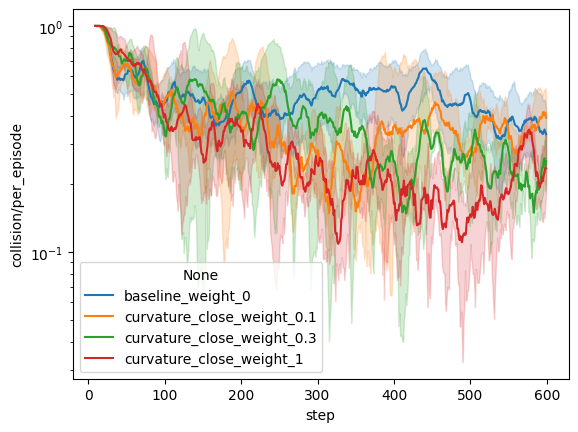

In [12]:
to_show = (
    data_pivot[data_pivot["run_category"].isin(["baseline", "curvature_close"])]
    .groupby(RUN_COLUMNS)
    .rolling(10, on="step")
    .mean()
    .reset_index()
)
sns.lineplot(
    data=to_show,
    x="step",
    y="collision/per_episode",
    hue=to_show["run_category"] + "_weight_" + to_show["aux_weight"]
).set(yscale="log")

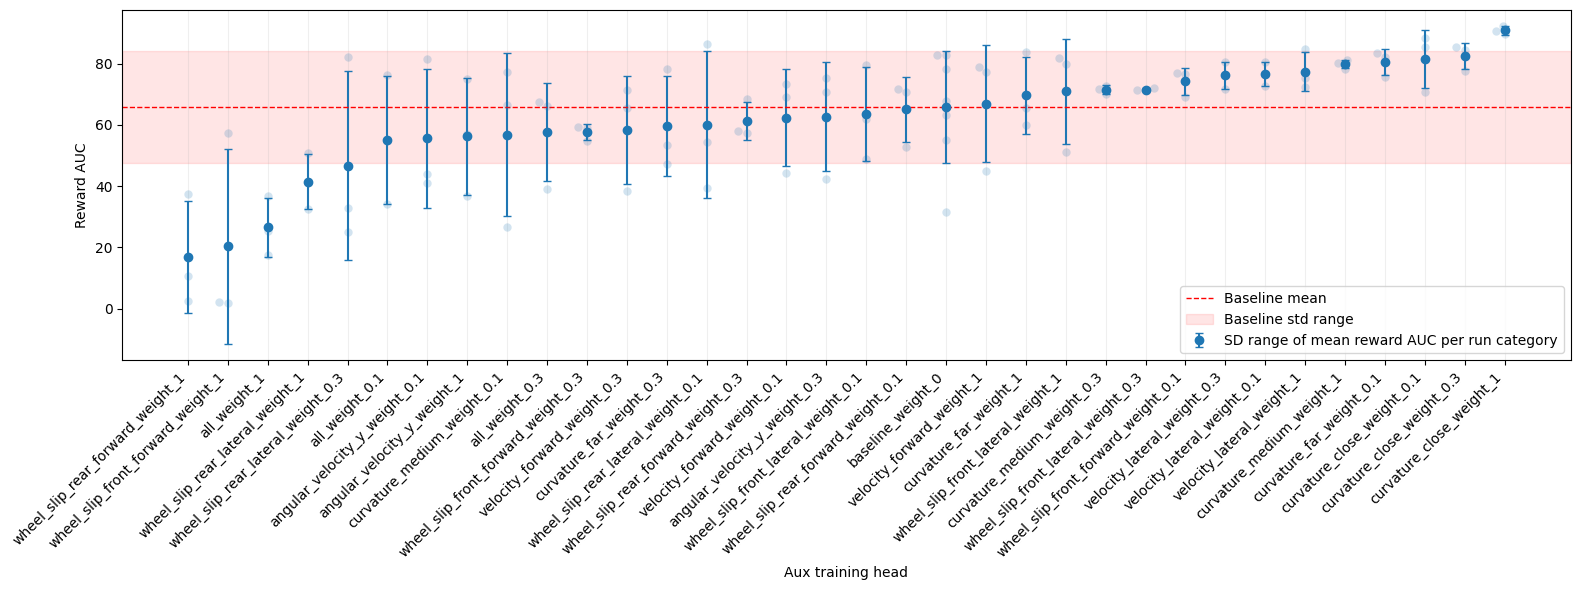

In [13]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std"]).reset_index().sort_values("mean")

base_mean = to_show[to_show["run_category"] == "baseline"][STAT].mean()
base_std = to_show_means[to_show_means["label"].str.contains("baseline")]["std"].mean()

order = to_show_means["label"].tolist()

plt.figure(figsize=(16, 6))

plt.errorbar(
    to_show_means["label"],
    to_show_means["mean"],
    yerr=to_show_means["std"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    x="label",
    y=STAT,
    order=order,
    legend=False,
    s=6,
    alpha=0.2
).set(xlabel="Aux training head", ylabel="Reward AUC")

sns.scatterplot(
    data=to_show_means,
    x="label",
    y="mean"
)

plt.grid(True, axis="x", alpha=0.2)

plt.axhline(base_mean, color="red", ls="--", lw=1, label="Baseline mean")
plt.axhspan(base_mean - base_std, base_mean + base_std,
            color="red", alpha=0.1, label="Baseline std range")

plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/auc_comparison.pdf", bbox_inches="tight")

In [16]:
last_50_means

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_metres,observation/forward_velocity,collision/per_progress_metres,collision/per_episode,collision/per_step
0,all,s0,0.1,0.175062,0.175292,4.091511,1.105359,0.193132,0.000199
1,all,s0,0.3,0.162019,0.162445,3.783238,1.935759,0.312783,0.000404
2,all,s0,1,0.103041,0.103117,2.365458,0.737286,0.075912,0.000068
3,all,s1,0.1,0.161085,0.161355,3.768374,1.408882,0.224590,0.000243
4,all,s1,0.3,0.171508,0.171848,4.017535,1.547222,0.265081,0.000314
...,...,...,...,...,...,...,...,...,...
101,wheel_slip_rear_lateral,s1,0.3,0.174625,0.175082,4.083489,2.013902,0.349578,0.000420
102,wheel_slip_rear_lateral,s1,1,0.057452,0.062309,1.519496,16.283747,0.958309,0.004705
103,wheel_slip_rear_lateral,s2,0.1,0.135647,0.137165,3.240141,5.018790,0.684064,0.001437
104,wheel_slip_rear_lateral,s2,0.3,0.098033,0.099730,2.366499,7.736436,0.741927,0.001644


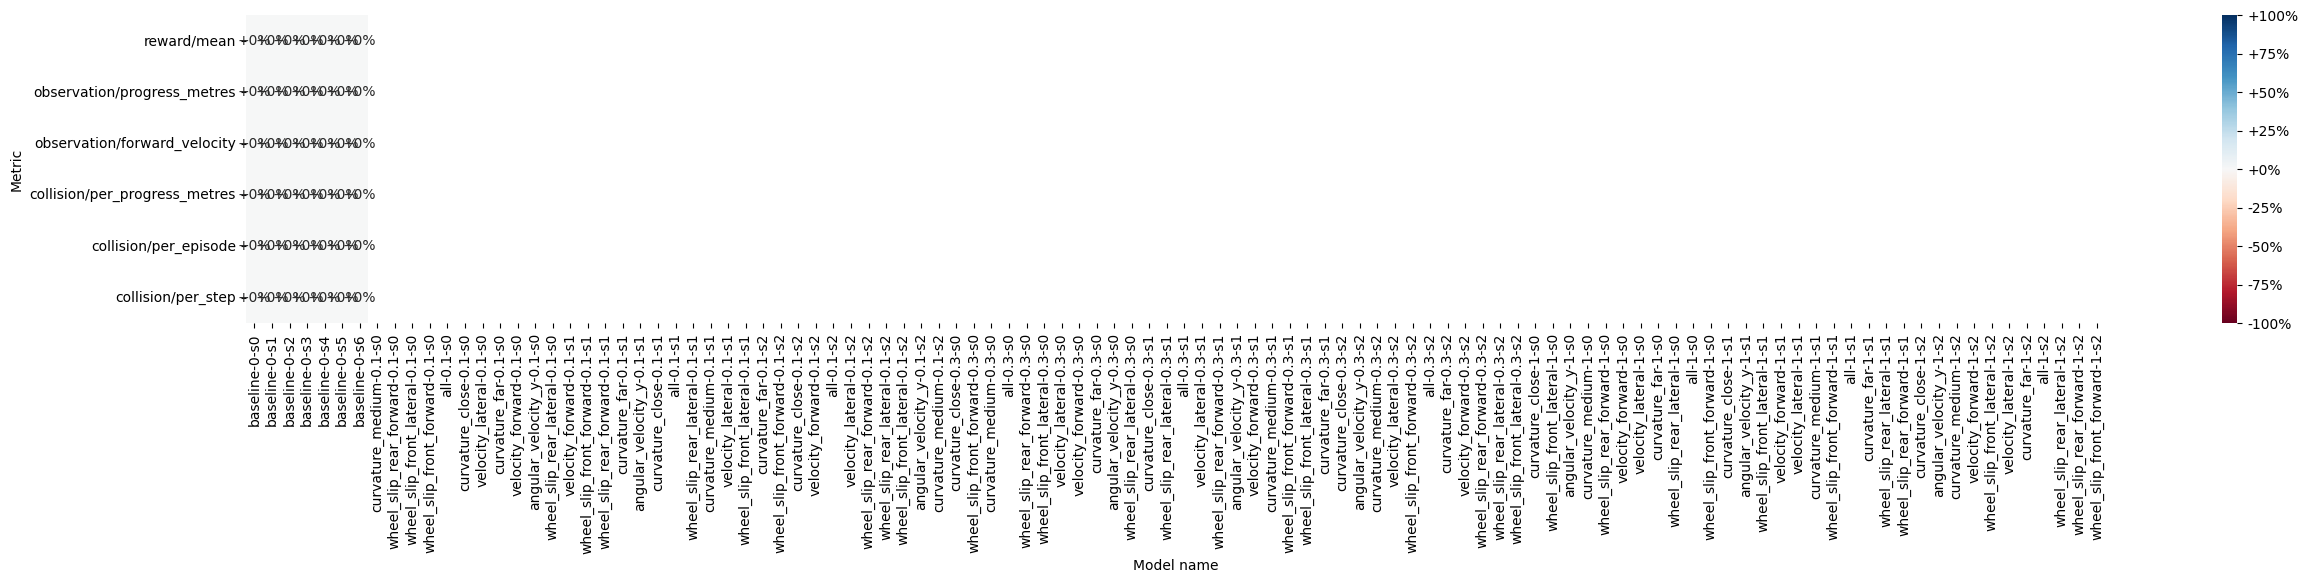

In [ ]:
to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)
baseline = to_show.loc["baseline"].squeeze()

to_show = to_show.div(baseline, axis=1)
to_show -= 1
plt.figure(figsize=(30, 4))

sns.heatmap(
    to_show.T, 
    annot=True, 
    fmt="+.0%", 
    cmap="RdBu", 
    center=0,
    vmax=1.0,
    vmin=-1.0,
    cbar_kws={
        "format": FuncFormatter(lambda x, _: f"{x:+.0%}"),
    }
).set(xlabel="Model name", ylabel="Metric")

plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")